# Traffic Sign Recognition: SVM versus CNN

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Compare classical image features and convolutional models for road-sign classification.

**Approach:** OpenCV/HOG + SVM contrasted with a CNN.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


In [70]:
import os
import cv2
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
import xml.etree.ElementTree as ET

# Set parameters
IMG_SIZE = (64, 64)
BATCH_SIZE = 32
EPOCHS = 15

# Class labels for the dataset
label_dict = {name: idx for idx, name in enumerate([
    'Speed limit (5km/h)', 'Speed limit (15km/h)', 'Speed limit (30km/h)', 
    'Speed limit (40km/h)', 'Speed limit (50km/h)', 'Speed limit (60km/h)', 
    'Speed limit (70km/h)', 'Speed limit (80km/h)', "Don't Go straight or left", 
    "Don't Go straight or Right", "Don't Go straight", "Don't Go Left", 
    "Don't Go Left or Right", "Don't Go Right", "Don't overtake from Left", 
    'No Uturn', 'No Car', 'No horn', 'Speed limit (40km/h)', 'Speed limit (50km/h)', 
    'Go straight or right', 'Go straight', 'Go Left', 'Go Left or right', 'Go Right', 
    'keep Left', 'keep Right', 'Roundabout mandatory', 'watch out for cars', 
    'Horn', 'Bicycles crossing', 'Uturn', 'Road Divider', 'Traffic signals', 'Danger Ahead', 
    'Zebra Crossing', 'Bicycles crossing', 'Children crossing', 'Dangerous curve to the left', 
    'Dangerous curve to the right', 'Unknown1', 'Unknown2', 'Unknown3', 'Go right or straight', 
    'Go left or straight', 'Unknown4', 'ZigZag Curve', 'Train Crossing', 'Under Construction', 
    'Unknown5', 'Fences', 'Heavy Vehicle Accidents', 'Unknown6', 'Give Way', 'No stopping', 
    'No entry', 'Unknown7', 'Unknown8'
])}
label_mapping = {
    0: 'Speed limit (5km/h)',
    1: 'Speed limit (15km/h)',
    2: 'Speed limit (30km/h)',
    3: 'Speed limit (40km/h)',
    4: 'Speed limit (50km/h)',
    5: 'Speed limit (60km/h)',
    6: 'Speed limit (70km/h)',
    7: 'Speed limit (80km/h)',
    8: "Don't Go straight or left",
    9: "Don't Go straight or Right",
    10: "Don't Go straight",
    11: "Don't Go Left",
    12: "Don't Go Left or Right",
    13: "Don't Go Right",
    14: 'Don\'t overtake from Left',
    15: 'No Uturn',
    16: 'No Car',
    17: 'No horn',
    18: 'Speed limit (40km/h)',
    19: 'Speed limit (50km/h)',
    20: 'Go straight or right',
    21: 'Go straight',
    22: 'Go Left',
    23: 'Go Left or right',
    24: 'Go Right',
    25: 'keep Left',
    26: 'keep Right',
    27: 'Roundabout mandatory',
    28: 'watch out for cars',
    29: 'Horn',
    30: 'Bicycles crossing',
    31: 'Uturn',
    32: 'Road Divider',
    33: 'Traffic signals',
    34: 'Danger Ahead',
    35: 'Zebra Crossing',
    36: 'Bicycles crossing',
    37: 'Children crossing',
    38: 'Dangerous curve to the left',
    39: 'Dangerous curve to the right',
    40: 'Unknown1',
    41: 'Unknown2',
    42: 'Unknown3',
    43: 'Go right or straight',
    44: 'Go left or straight',
    45: 'Unknown4',
    46: 'ZigZag Curve',
    47: 'Train Crossing',
    48: 'Under Construction',
    49: 'Unknown5',
    50: 'Fences',
    51: 'Heavy Vehicle Accidents',
    52: 'Unknown6',
    53: 'Give Way',
    54: 'No stopping',
    55: 'No entry',
    56: 'Unknown7',
    57: 'Unknown8'
}

In [77]:

# Preprocess dataset from folder hierarchy
def load_images_from_folders(base_path):
    X, y = [], []
    label_mapping = {}
    current_label = 0
    
    for folder in os.listdir(base_path):
        folder_path = os.path.join(base_path, folder)
        if os.path.isdir(folder_path):
            label_mapping[current_label] = folder
            for img_file in os.listdir(folder_path):
                img_path = os.path.join(folder_path, img_file)
                img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
                if img is not None:
                    img_resized = cv2.resize(img, IMG_SIZE)
                    X.append(img_resized)
                    y.append(current_label)
            current_label += 1
    
    return np.array(X), np.array(y), label_mapping

# Preprocess dataset from XML annotations
def load_images_from_annotations(image_dir, annotation_dir):
    X, y = [], []
    label_mapping = {}
    current_label = 0

    for annotation_file in os.listdir(annotation_dir):
        if annotation_file.endswith('.xml'):
            tree = ET.parse(os.path.join(annotation_dir, annotation_file))
            img_path = os.path.join(image_dir, annotation_file.replace('.xml', '.png'))
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            for obj in tree.getroot().findall('object'):
                class_name = obj.find('name').text.lower()
                if class_name not in label_mapping.values():
                    label_mapping[current_label] = class_name
                    current_label += 1
                label = list(label_mapping.keys())[list(label_mapping.values()).index(class_name)]
                xmin, ymin, xmax, ymax = map(int, [obj.find('bndbox').find(c).text for c in ['xmin', 'ymin', 'xmax', 'ymax']])
                cropped_img = img[ymin:ymax, xmin:xmax]
                img_resized = cv2.resize(cropped_img, IMG_SIZE)
                X.append(img_resized)
                y.append(label)
    
    return np.array(X), np.array(y), label_mapping

# Load datasets
data_path_1 = r"C:\Users\Dingue\TPRM2Dataset2\archive2\traffic_Data\DATA"
labels_csv_path = r"labels.csv"
image_dir_2 = r"C:\Users\Dingue\Desktop\TP Reasaux\RM2\archive\images"
annotation_dir_2 = r"C:\Users\Dingue\Desktop\TP Reasaux\RM2\archive\annotations"

X1, y1, label_mapping_1 = load_images_from_folders(data_path_1)
X2, y2, label_mapping_2 = load_images_from_annotations(image_dir_2, annotation_dir_2)

# Combine datasets
X = np.concatenate((X1, X2))
y = np.concatenate((y1, y2))
label_mapping = {**label_mapping_1, **{k + len(label_mapping_1): v for k, v in label_mapping_2.items()}}

# Normalize and reshape data
X = X / 255.0
X = X.reshape(-1, IMG_SIZE[0], IMG_SIZE[1], 1)
y = to_categorical(y, num_classes=len(label_mapping))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define CNN model
def create_cnn(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Train the model
model = create_cnn((IMG_SIZE[0], IMG_SIZE[1], 1), len(label_mapping))
history = model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_data=(X_test, y_test))

# Evaluate the model
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)




Epoch 1/15
136/136 [==============================] - 8s 55ms/step - loss: 2.1463 - accuracy: 0.5068 - val_loss: 0.8408 - val_accuracy: 0.8264
Epoch 2/15
136/136 [==============================] - 8s 56ms/step - loss: 0.5438 - accuracy: 0.8723 - val_loss: 0.4116 - val_accuracy: 0.9049
Epoch 3/15
136/136 [==============================] - 8s 58ms/step - loss: 0.1938 - accuracy: 0.9520 - val_loss: 0.1727 - val_accuracy: 0.9575
Epoch 4/15
136/136 [==============================] - 7s 54ms/step - loss: 0.0756 - accuracy: 0.9813 - val_loss: 0.1217 - val_accuracy: 0.9760
Epoch 5/15
136/136 [==============================] - 7s 54ms/step - loss: 0.0316 - accuracy: 0.9935 - val_loss: 0.1495 - val_accuracy: 0.9732
Epoch 6/15
136/136 [==============================] - 7s 54ms/step - loss: 0.0190 - accuracy: 0.9954 - val_loss: 0.0977 - val_accuracy: 0.9843
Epoch 7/15
136/136 [==============================] - 7s 54ms/step - loss: 0.0195 - accuracy: 0.9961 - val_loss: 0.0938 - val_accuracy: 0.9834

## Accuracy of the model

In [85]:
# Evaluate the model on the test data
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Accuracy: {accuracy * 100:.2f}%")


34/34 [==============================] - 0s 10ms/step - loss: 0.1271 - accuracy: 0.9843
Accuracy: 98.43%


In [78]:

print("Classification Report:\n", classification_report(y_test_classes, y_pred_classes))
conf_matrix = confusion_matrix(y_test_classes, y_pred_classes)


Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.91      0.95        64
           1       0.99      0.98      0.99       163
           2       0.95      1.00      0.97        53
           3       0.94      1.00      0.97        45
           4       1.00      1.00      1.00        22
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00        24
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00        33
           9       1.00      1.00      1.00        27
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         1
          12       1.00      1.00      1.00        11
          13       0.60      1.00      0.75         3
          14       1.00      0.60      0.75         5
          15       1.00      1.00      1.00         5
          16       1.00      1.00      1.00         2
   

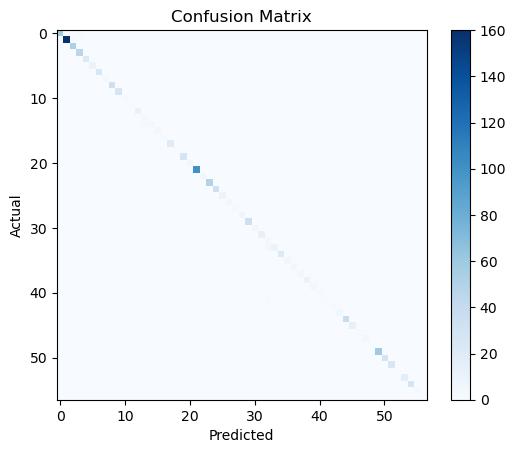

In [79]:
# Plot confusion matrix
plt.imshow(conf_matrix, cmap="Blues", interpolation="nearest")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [80]:

# Predict a single image
def predict_single_image(model, image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Image {image_path} not found.")
    img_resized = cv2.resize(img, IMG_SIZE) / 255.0
    img_resized = img_resized.reshape(1, IMG_SIZE[0], IMG_SIZE[1], 1)
    prediction = model.predict(img_resized)
    predicted_label = np.argmax(prediction)
    return label_mapping[predicted_label]

In [81]:

# Test a sample image
test_image_path = r"001_0006.png"
try:
    predicted_label = predict_single_image(model, test_image_path)
    print(f"Predicted label: {predicted_label}")
except ValueError as e:
    print(f"Error: {e}")

1/1 [==============================] - 0s 14ms/step
Predicted label: 1


1/1 [==============================] - 0s 15ms/step
Predicted label: 0


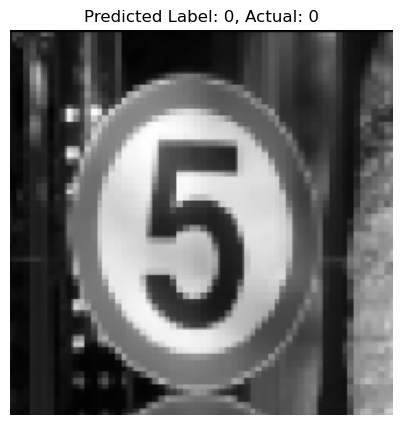

In [82]:

# Test a sample image
test_image_path = r"000_111.png"

try:
    predicted_label = predict_single_image(model, test_image_path)
    print(f"Predicted label: {predicted_label}")
    
    # Load the image using OpenCV or PIL
    image = cv2.imread(test_image_path)
    
    # Plot the image with the predicted label
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(f"Predicted Label: {predicted_label}, Actual: {np.argmax(y_test[51])}")
    plt.axis("off")  # Hide axis ticks
    plt.show()
except ValueError as e:
    print(f"Error: {e}")

1/1 [==============================] - 0s 14ms/step


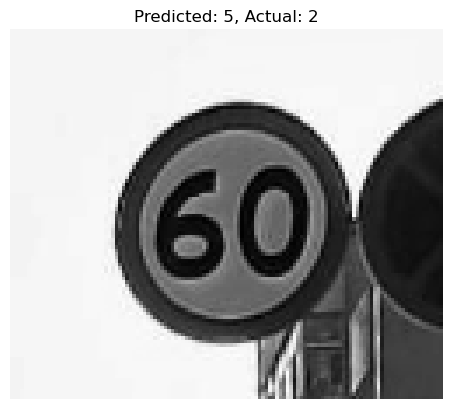

In [83]:
# Set test image path
test_path = r"C:\Users\Dingue\TPRM2Dataset2\archive2\traffic_Data\TEST"
img_files = os.listdir(test_path)

# Select a specific test image (240th in the list)
img_path = os.path.join(test_path, img_files[240])
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

# Preprocess the image
IMG_SIZE = (64, 64)
if img is not None:
    img_resized = cv2.resize(img, IMG_SIZE) / 255.0
    img_resized = img_resized.reshape(1, IMG_SIZE[0], IMG_SIZE[1], 1)
    prediction = model.predict(img_resized)
    predicted_label = np.argmax(prediction, axis=1)[0]

# Plot the test image
plt.imshow(img, cmap='gray')
plt.title(f"Predicted: {label_mapping.get(predicted_label, 'Unknown')}, Actual: {np.argmax(y_test[2])}")
plt.axis('off')
plt.show()